In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [4]:
df=pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.shape

(7043, 21)

In [6]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [7]:
overview = pd.DataFrame({
    "dtype": df.dtypes,
    "missing": df.isna().sum(),
    "unique_values": df.nunique()
})
display(overview)

,dtype,missing,unique_values
customerID,str,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
if "customerID" in df.columns:
    customer_ids = df["customerID"].dropna()
    print("Repeated customer IDs:", customer_ids.duplicated().sum())

Repeated customer IDs: 0


In [10]:
eda = df.copy()

raw_charges = eda["TotalCharges"].astype("string").str.strip()
blank_charges = raw_charges.eq("").fillna(False)

numeric_charges = pd.to_numeric(
    raw_charges.mask(blank_charges),
    errors="coerce"
)

invalid_charges = (
    raw_charges.notna() & ~blank_charges & numeric_charges.isna()
)

display(pd.Series({
    "Already missing": raw_charges.isna().sum(),
    "Blank strings": blank_charges.sum(),
    "Other invalid values": invalid_charges.sum()
}))


Already missing          0
Blank strings           11
Other invalid values     0
dtype: int64

In [11]:
display(eda["Churn"].value_counts(dropna=False))


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [12]:
display(eda["Churn"].value_counts(dropna=False))

label = eda["Churn"].astype("string").str.strip().str.lower()
eda["churn_flag"] = label.map({"no": 0, "yes": 1})

target = eda["churn_flag"].map({0: "Stayed", 1: "Churned"})
target.value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

churn_flag
Stayed     5174
Churned    1869
Name: count, dtype: int64

In [13]:
for column in ["Contract", "gender", "SeniorCitizen"]:
    summary = eda.groupby(column)["churn_flag"].agg(
        customers="size",
        churn_rate="mean"
    )
    summary["churn_rate"] = (summary["churn_rate"] * 100).round(2)
    display(summary)

,customers,churn_rate
Contract,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83


,customers,churn_rate
gender,,
Female,3488,26.92
Male,3555,26.16


,customers,churn_rate
SeniorCitizen,,
0,5901,23.61
1,1142,41.68


In [14]:
eda["TotalCharges"] = numeric_charges

display(
    eda.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]]
    .median()
    .round(2)
)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.43,1683.6
Yes,10.0,79.65,703.55


In [17]:
eda.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
tenure,7043.0,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.8,401.45,1397.475,3794.7375,8684.8
churn_flag,7043.0,0.26537,0.441561,0.0,0.0,0.0,1.0,1.0


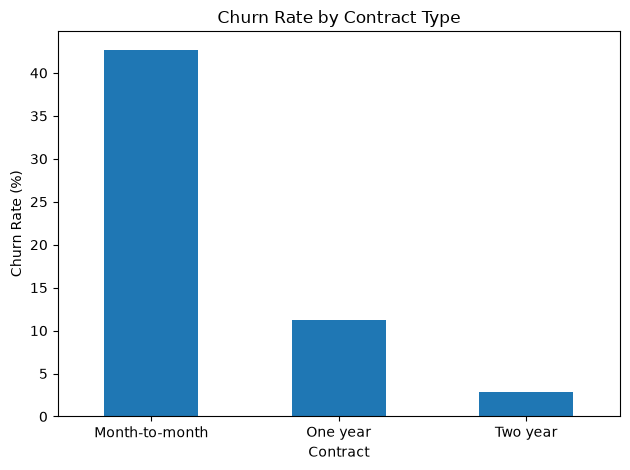

In [15]:
contract_churn = eda.groupby("Contract")["churn_flag"].mean() * 100

contract_churn.plot.bar(
    title="Churn Rate by Contract Type",
    ylabel="Churn Rate (%)",
    rot=0
)
plt.tight_layout()
plt.show()